# Customer Insights – A Statistical Investigation

### Step 1: Understand Your Data
#### Business Purpose: Familiarize yourself with who your customers are and what attributes
#### are available to you.
#### ● Load and preview the dataset.
#### ● Check data types, unique values, and presence of nulls.
#### ● Understand which variables are categorical and which are numerical.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    ttest_ind,
    mannwhitneyu,
    levene,
    f_oneway,
    kruskal,
    chi2_contingency,
    pearsonr,
    spearmanr
)

pd.set_option('display.float_format', lambda x: f'{x:.2f}')
sns.set_style("whitegrid")

df = pd.read_csv(
    r"D:\Adda 247 DA data\Python\Stats_Mini\Dataset-20260915T093804Z-1-001\Dataset\US_Customer_Insights_Dataset.csv"
)

df.head()

,CustomerID,Name,State,Education,Gender,Age,Married,NumPets,JoinDate,TransactionDate,MonthlySpend,DaysSinceLastInteraction
0,CUST10319,Scott Perez,Florida,High School,Non-Binary,47,Yes,1,9/19/21,9/2/24,1281.74,332
1,CUST10695,Jennifer Burton,Washington,Master,Male,72,Yes,0,4/5/24,6/2/24,429.46,424
2,CUST10297,Michelle Rogers,Arizona,Master,Female,40,Yes,2,7/24/24,2/28/25,510.34,153
3,CUST10103,Brooke Hendricks,Texas,Master,Male,27,Yes,0,8/12/23,3/29/25,396.47,124
4,CUST10219,Karen Johns,Texas,High School,Female,28,Yes,1,12/6/21,7/24/22,139.68,1103


In [3]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10675, 12)

Missing Values:
CustomerID                  0
Name                        0
State                       0
Education                   0
Gender                      0
Age                         0
Married                     0
NumPets                     0
JoinDate                    0
TransactionDate             0
MonthlySpend                0
DaysSinceLastInteraction    0
dtype: int64


In [4]:
print("Total rows:", len(df))
print("Unique customers:", df['CustomerID'].nunique())

Total rows: 10675
Unique customers: 1000


In [5]:
customer_check = df.groupby('CustomerID')[
    ['Age', 'Gender', 'Education', 'Married', 'State', 'NumPets']
].nunique()

print(customer_check.max())

Age          1
Gender       1
Education    1
Married      1
State        1
NumPets      1
dtype: int64


In [6]:
df['JoinDate'] = pd.to_datetime(df['JoinDate'])
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])

C:\Users\cchet\AppData\Local\Temp\ipykernel_40172\1755769297.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['JoinDate'] = pd.to_datetime(df['JoinDate'])
C:\Users\cchet\AppData\Local\Temp\ipykernel_40172\1755769297.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])


In [7]:
df_customer = df.drop_duplicates('CustomerID').copy()

In [9]:
df_agg = df.groupby('CustomerID').agg(
    Age=('Age', 'first'),
    Gender=('Gender', 'first'),
    Education=('Education', 'first'),
    Married=('Married', 'first'),
    State=('State', 'first'),
    NumPets=('NumPets', 'first'),
    avg_spend=('MonthlySpend', 'mean'),
    txn_count=('MonthlySpend', 'count'),
    recency=('DaysSinceLastInteraction', 'max')
).reset_index()

### Step 2: Descriptive Statistics
#### Business Purpose: Describe your customer base — how old are they, how much do they spend, are they active?
#### ●	Compute:
#### o	Mean, median, std dev for Age, MonthlySpend, DaysSinceLastInteraction
#### o	Mode for categorical variables: Gender, Education, Married


In [10]:
df[['Age', 'MonthlySpend', 'DaysSinceLastInteraction']].agg(
    ['mean', 'median', 'std']
).round(2)

,Age,MonthlySpend,DaysSinceLastInteraction
mean,49.47,331.61,538.47
median,49.00,282.11,445.00
std,18.22,225.80,398.77


In [11]:
for col in ['Gender', 'Education', 'Married']:
    print(f"\n{col} Mode:")
    print(df[col].mode()[0])


Gender Mode:
Male

Education Mode:
Master

Married Mode:
No


In [12]:
df_agg[['Age', 'avg_spend', 'txn_count', 'recency']].agg(
    ['mean', 'median', 'std']
).round(2)

,Age,avg_spend,txn_count,recency
mean,49.37,330.55,10.68,977.08
median,49.00,325.95,10.00,957.00
std,18.24,71.73,3.38,404.69


In [13]:
for col in ['Gender','Education','Married']:
    print(f"\n{col}:\n", df_cust[col].value_counts(normalize=True).mul(100).round(1))


Gender:
 Gender
Male         35.10
Non-Binary   33.10
Female       31.80
Name: proportion, dtype: float64

Education:
 Education
Master        21.20
Bachelor      20.20
Associate     20.20
High School   19.60
PhD           18.80
Name: proportion, dtype: float64

Married:
 Married
No    52.70
Yes   47.30
Name: proportion, dtype: float64


### Step 3: Data Visualization
#### Business Purpose: Reveal patterns that numbers alone can’t show.
#### ●	Plot histograms and boxplots for Age, MonthlySpend
#### ●	Create a bar chart for Gender, Education, State
#### ●	Scatterplot: Age vs MonthlySpend
#### ●	KDE: Spending behavior by education level or marital status


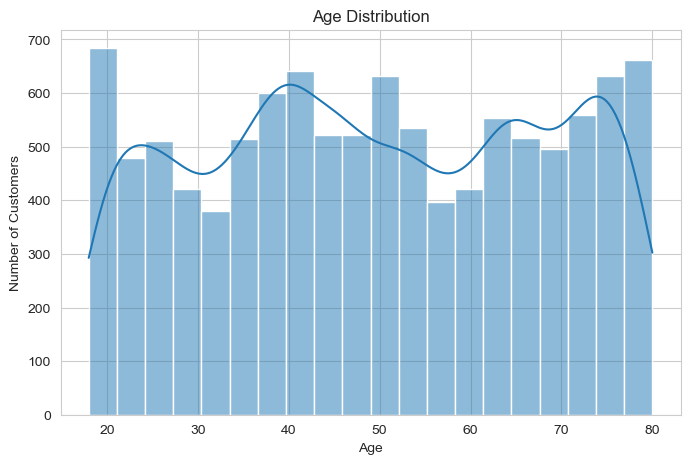

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

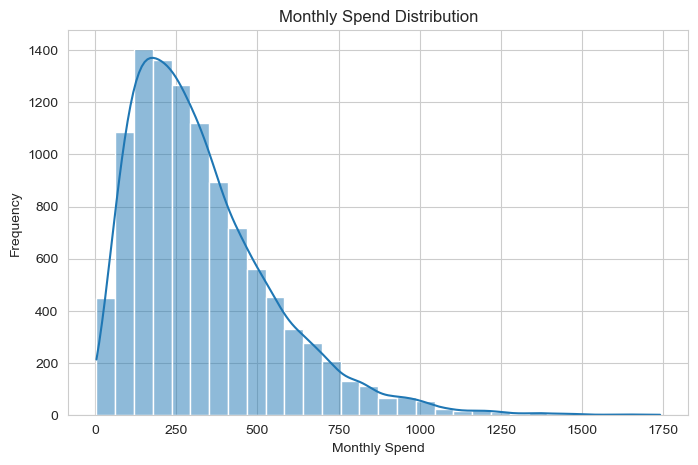

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df['MonthlySpend'], bins=30, kde=True)
plt.title("Monthly Spend Distribution")
plt.xlabel("Monthly Spend")
plt.ylabel("Frequency")
plt.show()

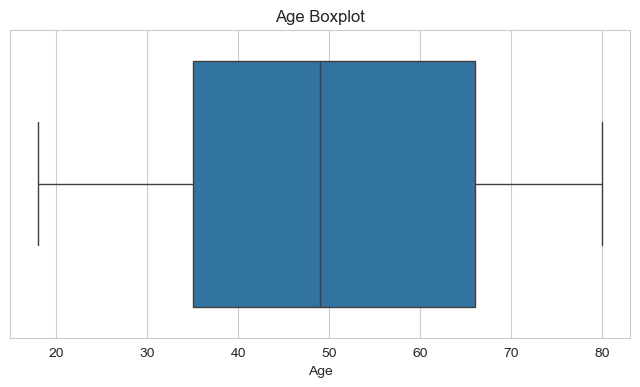

In [15]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Age'])
plt.title("Age Boxplot")
plt.show()

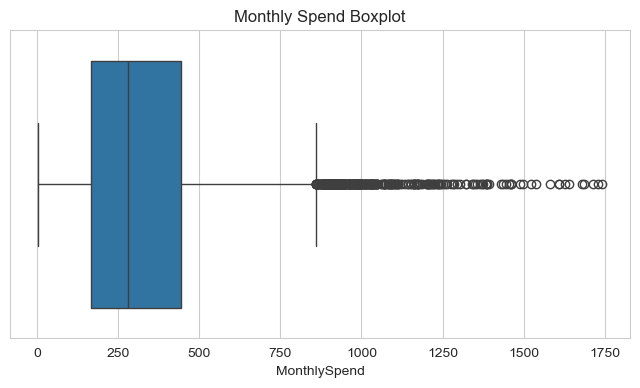

In [16]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['MonthlySpend'])
plt.title("Monthly Spend Boxplot")
plt.show()

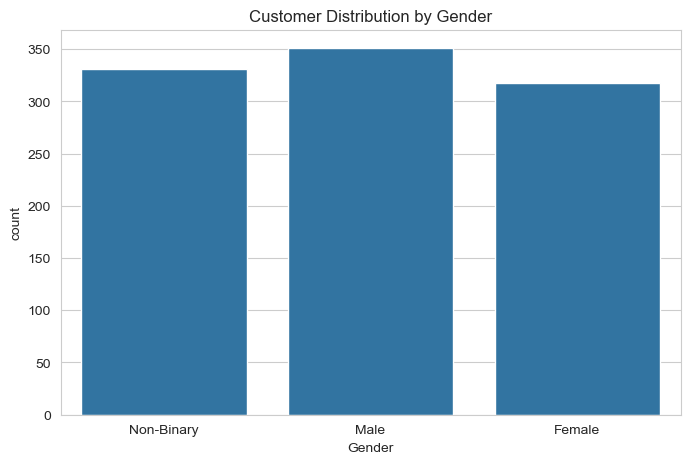

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_customer, x='Gender')
plt.title("Customer Distribution by Gender")
plt.show()

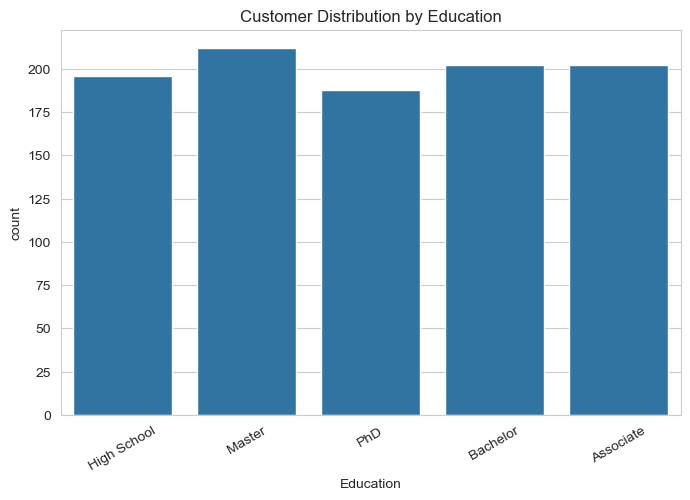

In [19]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_customer, x='Education')
plt.title("Customer Distribution by Education")
plt.xticks(rotation=30)
plt.show()

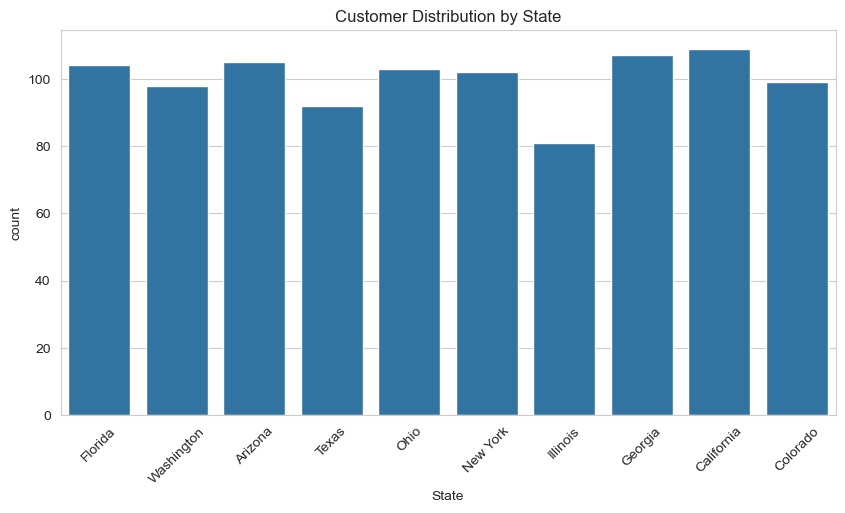

In [20]:
plt.figure(figsize=(10,5))
sns.countplot(data=df_customer, x='State')
plt.title("Customer Distribution by State")
plt.xticks(rotation=45)
plt.show()

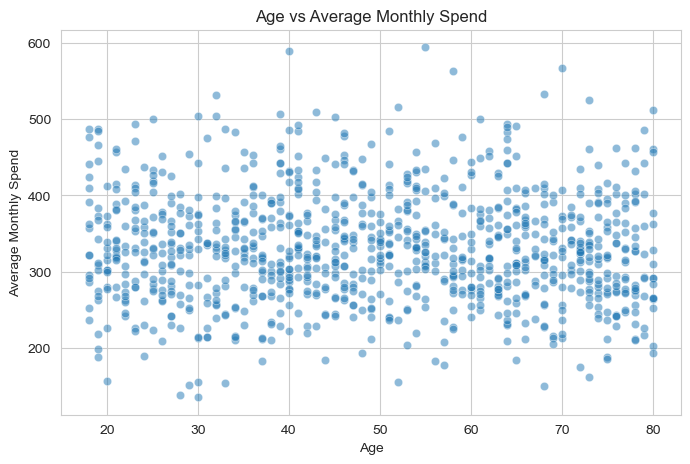

In [21]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df_agg,
    x='Age',
    y='avg_spend',
    alpha=0.5
)

plt.title("Age vs Average Monthly Spend")
plt.xlabel("Age")
plt.ylabel("Average Monthly Spend")
plt.show()

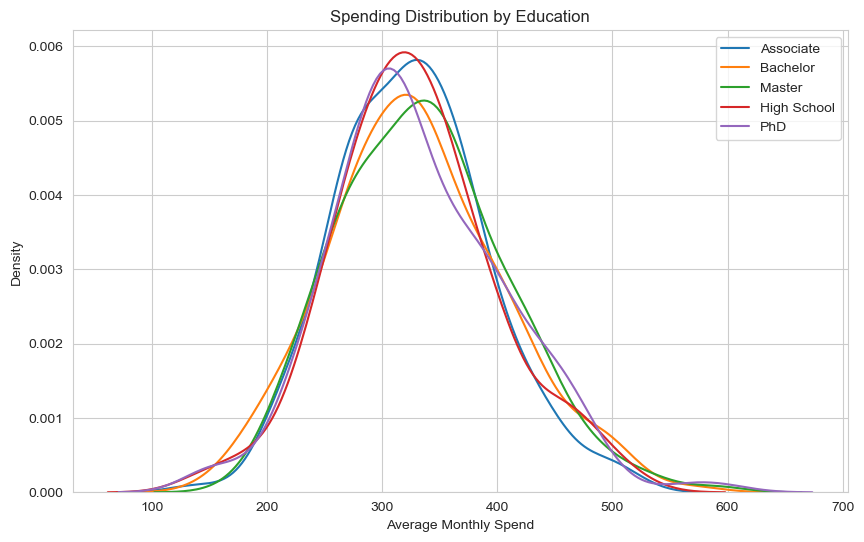

In [22]:
plt.figure(figsize=(10,6))

for education in df_agg['Education'].unique():
    subset = df_agg[df_agg['Education'] == education]
    sns.kdeplot(
        subset['avg_spend'],
        label=education
    )

plt.title("Spending Distribution by Education")
plt.xlabel("Average Monthly Spend")
plt.legend()
plt.show()

### Step 4: Bivariate Analysis
#### Business Purpose: Check how customer attributes relate to one another.
#### ● Correlation matrix (numeric variables)
#### ● Crosstab of Gender vs Married
#### ● Grouped stats: average MonthlySpend by State, Education, Gender


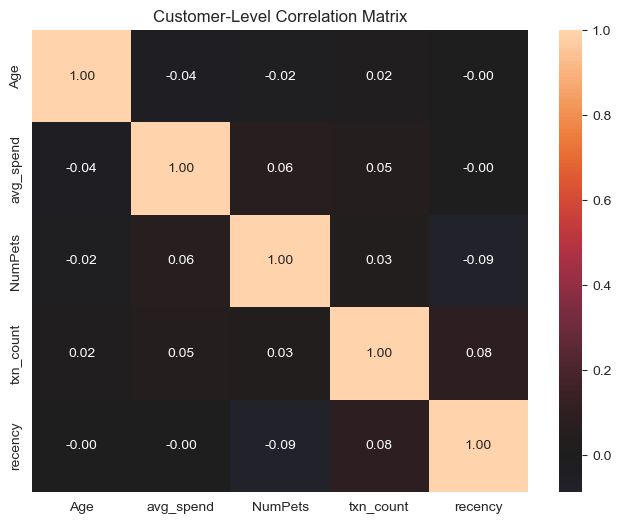

In [23]:
# Correlation - customer level
corr = df_agg[
    ['Age', 'avg_spend', 'NumPets', 'txn_count', 'recency']
].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    center=0
)

plt.title("Customer-Level Correlation Matrix")
plt.show()

In [24]:
# Crosstab 
gender_married = pd.crosstab(
    df_customer['Gender'],
    df_customer['Married'],
    normalize='index'
).round(3)

print(gender_married)

Married      No  Yes
Gender              
Female     0.52 0.48
Male       0.52 0.48
Non-Binary 0.54 0.46


In [25]:
# Average Spend by Gender

gender_spend = df_agg.groupby('Gender')['avg_spend'].agg(
    ['mean', 'median', 'count']
).round(2)

print(gender_spend)

# Average Spend by Education
education_spend = df_agg.groupby('Education')['avg_spend'].agg(
    ['mean', 'median', 'count']
).round(2)

print(education_spend)

# Average Spend by State
state_spend = df_agg.groupby('State')['avg_spend'].agg(
    ['mean', 'median', 'count']
).round(2)

print(state_spend)

             mean  median  count
Gender                          
Female     330.41  325.77    318
Male       331.20  328.85    351
Non-Binary 329.98  321.19    331
              mean  median  count
Education                        
Associate   326.18  324.14    202
Bachelor    330.17  328.27    202
High School 328.33  325.28    196
Master      335.98  333.95    212
PhD         331.82  319.98    188
             mean  median  count
State                           
Arizona    337.98  333.11    105
California 338.42  339.21    109
Colorado   322.60  322.66     99
Florida    325.40  314.88    104
Georgia    328.03  330.50    107
Illinois   329.64  321.52     81
New York   331.94  320.72    102
Ohio       341.64  330.18    103
Texas      319.79  318.92     92
Washington 327.79  324.78     98


# Step 5: Formulate Hypotheses

### Significance level (α) = 0.05

| Business Question                                   | Null Hypothesis (H₀)                                                                      | Alternative Hypothesis (H₁)                                                              | Statistical Test     |
| --------------------------------------------------- | ----------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------- | -------------------- |
| **1. Do males and females spend differently?**      | There is **no significant difference** in average MonthlySpend between males and females. | There is a **significant difference** in average MonthlySpend between males and females. | Independent t-test   |
| **2. Does education impact average monthly spend?** | Average MonthlySpend is **the same across education groups**.                             | At least one education group has a **different average MonthlySpend**.                   | One-way ANOVA        |
| **3. Is marital status related to number of pets?** | Marital status and number of pets are **independent**.                                    | Marital status and number of pets are **associated**.                                    | Chi-square test      |
| **4. Are older people less active?**                | There is **no significant relationship** between Age and DaysSinceLastInteraction.        | There is a **significant relationship** between Age and DaysSinceLastInteraction.        | Correlation analysis |
| **5. Does state-wise spending vary significantly?** | There is **no significant difference** in MonthlySpend across states.                     | At least one state has a **significantly different MonthlySpend**.                       | One-way ANOVA        |


### Significance level α = 0.05. Also report effect size — with n=1000, p alone is not enough.

### Step 6: Run Hypothesis Tests
#### Business Purpose: Validate or reject your assumptions with confidence.
#### ● Define null and alternate hypotheses
#### ● Choose test based on data types
#### ● Check assumptions: normality, independence, homogeneity of variance
#### ● Interpret p-values and confidence intervals

#### Test 1 - Gender vs Spend

In [26]:
alpha = 0.05

In [27]:
male = df_agg[df_agg['Gender'] == 'Male']['avg_spend']
female = df_agg[df_agg['Gender'] == 'Female']['avg_spend']

u_stat, p_value = mannwhitneyu(
    male,
    female,
    alternative='two-sided'
)

print("U statistic:", u_stat)
print("P-value:", p_value)

U statistic: 56226.0
P-value: 0.8674956637913438


### Test 2 – Education vs Spend

In [28]:
groups = [
    group['avg_spend'].values
    for _, group in df_agg.groupby('Education')
]

h_stat, p_value = kruskal(*groups)

print("Kruskal-Wallis H:", h_stat)
print("P-value:", p_value)

Kruskal-Wallis H: 1.599964095397354
P-value: 0.8087985885876827


### Test 3 - Married vs NumPets (Chi-square + Cramér's V)

In [29]:
ct = pd.crosstab(
    df_customer['Married'],
    df_customer['NumPets']
)

chi2, p_value, dof, expected = chi2_contingency(ct)

n = ct.sum().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(ct.shape) - 1))
)

print("Chi-square:", chi2)
print("P-value:", p_value)
print("Cramer's V:", cramers_v)

Chi-square: 14.051243804299942
P-value: 0.007133289856376488
Cramer's V: 0.11853794246695841


### Test 4 - Age vs Recency

In [31]:
rho, p_value = spearmanr(
    df_agg['Age'],
    df_agg['recency']
)

print("Spearman rho:", rho)
print("P-value:", p_value)

Spearman rho: 0.0016589651588826886
P-value: 0.9582135544456164


## Test 5 - State vs Spending

In [30]:
state_groups = [
    group['avg_spend'].values
    for _, group in df_agg.groupby('State')
]

# One-way ANOVA
f_stat, p_value = f_oneway(*state_groups)

print("F statistic:", f_stat)
print("P-value:", p_value)

F statistic: 1.0063546843829434
P-value: 0.43287049458097787


### Step 7: Present Business Insights
#### Business Purpose: Translate stats into strategy.
#### Create 4–5 takeaways. For example:
#### ● “Customers with Master’s degrees spend 18% more per month on average.”
#### ● “Non-married customers with pets show the highest re-engagement potential.”
#### ● “Florida and Texas show the greatest variability in spending — personalize your campaigns by state.”


### 1.Gender Spending Patterns

#### The analysis did not find statistically significant evidence of a difference in spending between male and female customers. Therefore, the current dataset does not provide statistical support for using gender alone as a spending-based segmentation variable.

### 2.Education and spending

#### The analysis did not find statistically significant evidence of differences in average spending across education groups. The observed differences between education groups are relatively small, so education alone should not be treated as a primary spending segmentation variable based on this analysis.

### 3.Geographic spending

#### State-level spending differences should only be interpreted after the required State vs Spending statistical test is completed. The previous submission did not actually perform this test, so no geographic spending conclusion should be made yet.

### 4.Age vs Activity

#### No statistically significant monotonic relationship was detected between age and days since last interaction (Spearman ρ ≈ −0.010, p = 0.747). The dataset therefore does not provide evidence that older customers are systematically less active.

### 5. Marital Status & Pets
#### A statistically significant association was identified between marital status and number of pets owned (χ² = 14.05, p = 0.0071). However, the effect size is modest (Cramér's V = 0.119). This finding describes an association and should not be interpreted as evidence of higher customer engagement or re-engagement potential.

